# Evaluación del modelo CSI2PointCloud — dataset propio

Notebook de **test** para la tesis. Evalúa el modelo entrenado por `entrenar_tesis.ipynb`
sobre el conjunto de **test reservado** (el último 15 % cronológico de cada acción, que el
modelo nunca vio durante el entrenamiento).

Sigue el protocolo de `scripts/test_model.py` de **Määttä et al. (2025)**.

---

## Protocolo de métricas

| Métrica | Qué mide | Mejor |
|---|---|---|
| **ICP Fitness** | fracción de puntos con correspondencia dentro del umbral | ↑ alto |
| **ICP RMSE** | error cuadrático medio de esas correspondencias (m) | ↓ bajo |
| **Chamfer** | distancia bidireccional media entre las nubes (m) | ↓ bajo |
| **Tiempo/estimación** | latencia de inferencia (ms) | ↓ bajo |

**Umbral ICP:** se usa **0.02 m**, que es el valor por defecto de `icp_registration()` en
`test_model.py:166` — el mismo con el que se obtuvo la Tabla I del paper. Se reportan
además otros umbrales para ver cómo evoluciona.

> ### Sobre la comparación con el paper
>
> Las cifras de Määttä (fitness 0.6358, RMSE 0.0103 m) **no son directamente comparables**
> con las de este trabajo:
>
> | | Määttä | Este trabajo |
> |---|---|---|
> | Dataset | MM-Fi (40 sujetos, 27 acciones) | propio (1 sujeto, 6 acciones) |
> | Ground truth | LiDAR Ouster OS1 (32 canales) | Azure Kinect (ToF) |
> | Contenido | escena completa (persona + muebles + sala) | sujeto aislado |
> | Split | por sujeto (32/8) o por sala | cronológico por acción |
> | CSI | Atheros, 5 GHz | ESP32-S3, 2.4 GHz |
>
> Se incluyen como **referencia de orden de magnitud**, no como comparación directa.

## 1. Imports, rutas y modelo entrenado

In [1]:
import os, sys, glob, time, json
import numpy as np
import scipy.io as scio
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import open3d as o3d

AQUI = os.path.abspath(os.getcwd())
if AQUI not in sys.path:
    sys.path.append(AQUI)

from modelo.csi2pointcloud.csi2pointcloud_arch01 import CSI2PointCloudModel
from modelo.loss.mmslab_loss import CSI2PointCloudLoss

TESIS = os.path.abspath(os.path.join(AQUI, '..'))
DATA  = os.environ.get('CSI2PC_DATA', os.path.join(TESIS, 'mmfi_dataset'))
OUT   = os.environ.get('CSI2PC_OUT',  os.path.join(TESIS, 'pc', 'resultados'))
DATA, OUT = os.path.abspath(DATA), os.path.abspath(OUT)

CKPT  = os.path.join(OUT, 'modelo', 'csi2pc_v2.pth')
SPLIT = os.path.join(OUT, 'split.json')

print('Datos      :', DATA, ' <-- OK' if os.path.isdir(DATA) else ' <-- NO EXISTE')
print('Checkpoint :', CKPT, ' <-- OK' if os.path.exists(CKPT) else ' <-- NO EXISTE (corre entrenar_tesis.ipynb)')
print('Split      :', SPLIT, ' <-- OK' if os.path.exists(SPLIT) else ' <-- NO EXISTE')

assert os.path.exists(CKPT), 'Falta el modelo entrenado. Ejecuta primero entrenar_tesis.ipynb'
assert os.path.exists(SPLIT), 'Falta split.json. Ejecuta primero entrenar_tesis.ipynb'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('\nDevice     :', f'cuda ({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else 'cpu')

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Datos      : C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\mmfi_dataset  <-- OK
Checkpoint : C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados\modelo\csi2pc_v2.pth  <-- OK
Split      : C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados\split.json  <-- OK

Device     : cuda (NVIDIA RTX A5000)


## 2. Dataset y conjunto de test

Se reutiliza **exactamente el mismo split** que usó el entrenamiento, leyéndolo de
`split.json`. Así se garantiza que el test es el mismo conjunto reservado y que el modelo
nunca lo vio.

In [2]:
class CSIDataset(Dataset):
    """Pares (CSI, nube) en formato MM-Fi. Idéntico al del notebook de entrenamiento."""

    def __init__(self, root):
        self.items, self.actions = [], []
        for mat in sorted(glob.glob(os.path.join(root, '**', 'wifi-csi', '*.mat'), recursive=True)):
            binf = mat.replace('wifi-csi', 'lidar').replace('.mat', '.bin')
            if os.path.exists(binf):
                self.items.append((mat, binf))
                self.actions.append(os.path.basename(os.path.dirname(os.path.dirname(mat))))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        mat, binf = self.items[i]
        m = scio.loadmat(mat)
        amp = m['CSIamp'].astype(np.float64)
        pha = m['CSIphase'].astype(np.float64)
        amp[np.isinf(amp)] = np.nan
        pha[np.isinf(pha)] = np.nan
        if np.any(np.isnan(amp)):
            amp[np.isnan(amp)] = np.nanmean(amp)
        if np.any(np.isnan(pha)):
            pha[np.isnan(pha)] = np.nanmean(pha)
        amp = (amp - np.nanmin(amp)) / (np.nanmax(amp) - np.nanmin(amp) + 1e-9)

        csi = np.stack([amp, pha], axis=2).astype(np.float32)
        csi = (csi - csi.mean()) / (csi.std() + 1e-9)

        gt = np.frombuffer(open(binf, 'rb').read(), dtype=np.float64)
        gt = gt.reshape(-1, 3).astype(np.float32).copy()
        gt = (gt - gt.mean()) / (gt.std() + 1e-9)

        return torch.from_numpy(csi), torch.from_numpy(gt)


ds = CSIDataset(DATA)
sp = json.load(open(SPLIT))
te = sp['test']

print(f'Dataset completo : {len(ds)} pares')
print(f'Conjunto de TEST : {len(te)} frames  ({100*len(te)/len(ds):.0f} %)')
print(f'Split usado      : {sp["ratios"]}  (train/val/test)')
print('\nFrames de test por acción:')
acts_test = [ds.actions[i] for i in te]
for a in sorted(set(acts_test)):
    print(f'  {a}: {acts_test.count(a)}')

Dataset completo : 706 pares
Conjunto de TEST : 112 frames  (16 %)
Split usado      : [0.7, 0.15, 0.15]  (train/val/test)

Frames de test por acción:
  A01: 18
  A02: 20
  A03: 18
  A04: 19
  A05: 19
  A06: 18


## 3. Cargar el modelo entrenado

La arquitectura se reconstruye a partir de la config guardada dentro del propio checkpoint,
para que coincida siempre con la del entrenamiento (sea el preset `oficial` o `paper`).

In [3]:
ck = torch.load(CKPT, map_location=device, weights_only=False)
CFG = ck.get('config', {})

model = CSI2PointCloudModel(
    embedding_dim=CFG.get('embedding_dim', 256),
    num_heads=CFG.get('num_heads', 4),
    num_encoder_layers=CFG.get('num_encoder_layers', 3),
    num_decoder_layers=CFG.get('num_decoder_layers', 3),
    num_points=CFG.get('num_points', 1200),
    num_antennas=CFG.get('num_antennas', 3),
    num_subcarriers=CFG.get('num_subcarriers', 114),
    num_time_slices=CFG.get('num_time_slices', 10),
).to(device)
model.load_state_dict(ck['model_state_dict'])
model.eval()

print('[Modelo cargado]')
print(f'  Checkpoint   : época {ck.get("epochs", "?")}')
print(f'  Val loss     : {ck.get("val_loss", float("nan")):.4f}')
print(f'  Embedding    : {model.embedding_dim}')
print(f'  Capas enc/dec: {CFG.get("num_encoder_layers", "?")} / {CFG.get("num_decoder_layers", "?")}')
print(f'  Parámetros   : {sum(p.numel() for p in model.parameters()):,}')
if CFG:
    print(f'  Entrenado con: {CFG.get("epochs")} épocas, batch {CFG.get("batch_size")}, lr {CFG.get("lr")}')

[Modelo cargado]
  Checkpoint   : época 50
  Val loss     : 1027.5983
  Embedding    : 256
  Capas enc/dec: 3 / 3
  Parámetros   : 9,086,979
  Entrenado con: 50 épocas, batch 24, lr 0.0001


## 4. Inferencia sobre el test y tiempo por estimación

`test_model.py` mide el tiempo medio por estimación; el paper lo reporta en la Tabla I
(CPU 137.27 ms, GPU 2.31 ms). Aquí se mide igual, tras un *warm-up* para no contar la
inicialización de los kernels CUDA.

In [4]:
test_dl = DataLoader(Subset(ds, te), batch_size=24, shuffle=False)

# Warm-up (no se cronometra)
with torch.no_grad():
    x0, _ = ds[te[0]]
    for _ in range(3):
        model(x0.unsqueeze(0).to(device))
if device.type == 'cuda':
    torch.cuda.synchronize()

# --- Inferencia cronometrada ---
preds_norm, total_time, n = [], 0.0, 0
loss_fn = CSI2PointCloudLoss(chamfer_weight=0.85, regularization_weight=0.15)
perdidas = []

with torch.no_grad():
    for x, g in test_dl:
        x, g = x.to(device), g.to(device)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.time()
        pred, trans_feat = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        total_time += time.time() - t0
        n += x.size(0)
        perdidas.append(loss_fn(pred, g, trans_feat).item())
        preds_norm.append(pred.float().cpu().numpy().astype(np.float64))

preds_norm = np.concatenate(preds_norm, axis=0)
ms_por_frame = total_time / n * 1000

print(f'Frames evaluados      : {n}')
print(f'Pérdida test (Chamfer): {np.mean(perdidas):.4f}')
print(f'Tiempo total          : {total_time:.3f} s')
print(f'Tiempo por estimación : {ms_por_frame:.3f} ms  ({device.type.upper()})')
print(f'\nReferencia paper Tabla I: CPU 137.27 ms | GPU 2.31 ms')

Frames evaluados      : 112
Pérdida test (Chamfer): 1027.8002
Tiempo total          : 0.262 s
Tiempo por estimación : 2.343 ms  (CUDA)

Referencia paper Tabla I: CPU 137.27 ms | GPU 2.31 ms


## 5. Métricas ICP y Chamfer

Las predicciones se desnormalizan a **metros** usando la media y desviación del ground-truth
de cada frame, de modo que RMSE y Chamfer queden en unidades físicas reales.

In [5]:
def nube(P):
    """PointCloud de Open3D (requiere float64, contiguo y escribible)."""
    return o3d.geometry.PointCloud(
        o3d.utility.Vector3dVector(np.ascontiguousarray(P, dtype=np.float64)))


def nn_dist(A, B):
    """Distancia de cada punto de A a su vecino más cercano en B."""
    kdt = o3d.geometry.KDTreeFlann(nube(B))
    d = np.empty(len(A))
    for i, p in enumerate(A):
        _, _, d2 = kdt.search_knn_vector_3d(p, 1)
        d[i] = np.sqrt(d2[0])
    return d


def icp(pred, gt, thr):
    """ICP point-to-point, igual que icp_registration() de test_model.py."""
    reg = o3d.pipelines.registration.registration_icp(
        nube(pred), nube(gt), thr, np.identity(4),
        o3d.pipelines.registration.TransformationEstimationPointToPoint())
    return reg.fitness, reg.inlier_rmse


# Desnormalizar a metros con la escala del GT de cada frame
preds_m, gts = [], []
for k, i in enumerate(te):
    gt_raw = np.frombuffer(open(ds.items[i][1], 'rb').read(),
                           dtype=np.float64).reshape(-1, 3).copy()
    preds_m.append(preds_norm[k] * gt_raw.std() + gt_raw.mean())
    gts.append(gt_raw)

# Chamfer (no depende del umbral: se calcula una sola vez)
t0 = time.time()
chamfer = np.array([nn_dist(pm, gt).mean() + nn_dist(gt, pm).mean()
                    for pm, gt in zip(preds_m, gts)])
print(f'Chamfer calculado en {time.time()-t0:.1f}s\n')

UMBRAL_PAPER = 0.02   # valor por defecto de icp_registration() en test_model.py
UMBRALES = [0.01, UMBRAL_PAPER, 0.05, 0.10]

resultados = {}
for thr in UMBRALES:
    vals = np.array([icp(pm, gt, thr) for pm, gt in zip(preds_m, gts)])
    resultados[thr] = {'fitness': vals[:, 0], 'rmse': vals[:, 1]}

print(f'{"Umbral":>8} | {"ICP Fitness":>12} | {"ICP RMSE (m)":>13} | {"Chamfer (m)":>12}')
print('-' * 56)
for thr in UMBRALES:
    r = resultados[thr]
    marca = '  <-- umbral del paper' if thr == UMBRAL_PAPER else ''
    print(f'{thr:8.2f} | {r["fitness"].mean():12.4f} | {r["rmse"].mean():13.4f} | '
          f'{chamfer.mean():12.4f}{marca}')

Chamfer calculado en 0.8s



  Umbral |  ICP Fitness |  ICP RMSE (m) |  Chamfer (m)
--------------------------------------------------------
    0.01 |       0.0262 |        0.0070 |       0.1333
    0.02 |       0.1667 |        0.0146 |       0.1333  <-- umbral del paper
    0.05 |       0.8040 |        0.0311 |       0.1333
    0.10 |       0.9826 |        0.0385 |       0.1333


## 6. Desglose por acción

Permite ver si alguna acción concreta se reconstruye peor (p. ej. las de más movimiento).

In [6]:
NOMBRES = {'A01': 'estático', 'A02': 'brazos en cruz', 'A03': 'caminar en el sitio',
           'A04': 'agacharse', 'A05': 'girar torso', 'A06': 'estirar piernas'}

acts = np.array(acts_test)
r = resultados[UMBRAL_PAPER]

print(f'Umbral {UMBRAL_PAPER:.2f} m (el del paper)\n')
print(f'{"Acción":<24} | {"n":>3} | {"Fitness":>8} | {"RMSE (m)":>9} | {"Chamfer (m)":>11}')
print('-' * 70)

filas = []
for a in sorted(set(acts_test)):
    m = acts == a
    fila = (a, NOMBRES.get(a, ''), int(m.sum()),
            r['fitness'][m].mean(), r['rmse'][m].mean(), chamfer[m].mean())
    filas.append(fila)
    print(f'{a} {NOMBRES.get(a, ""):<20} | {int(m.sum()):3d} | {fila[3]:8.3f} | '
          f'{fila[4]:9.4f} | {fila[5]:11.4f}')

print('-' * 70)
print(f'{"GLOBAL":<24} | {len(te):3d} | {r["fitness"].mean():8.3f} | '
      f'{r["rmse"].mean():9.4f} | {chamfer.mean():11.4f}')

mejor = max(filas, key=lambda f: f[3])
peor  = min(filas, key=lambda f: f[3])
print(f'\nMejor: {mejor[0]} ({mejor[1]}) fitness {mejor[3]:.3f}')
print(f'Peor : {peor[0]} ({peor[1]}) fitness {peor[3]:.3f}')

Umbral 0.02 m (el del paper)

Acción                   |   n |  Fitness |  RMSE (m) | Chamfer (m)
----------------------------------------------------------------------
A01 estático             |  18 |    0.171 |    0.0146 |      0.1328
A02 brazos en cruz       |  20 |    0.176 |    0.0146 |      0.1198
A03 caminar en el sitio  |  18 |    0.144 |    0.0145 |      0.1374
A04 agacharse            |  19 |    0.168 |    0.0146 |      0.1498
A05 girar torso          |  19 |    0.172 |    0.0147 |      0.1260
A06 estirar piernas      |  18 |    0.168 |    0.0147 |      0.1349
----------------------------------------------------------------------
GLOBAL                   | 112 |    0.167 |    0.0146 |      0.1333

Mejor: A02 (brazos en cruz) fitness 0.176
Peor : A03 (caminar en el sitio) fitness 0.144


## 7. Gráficas de métricas

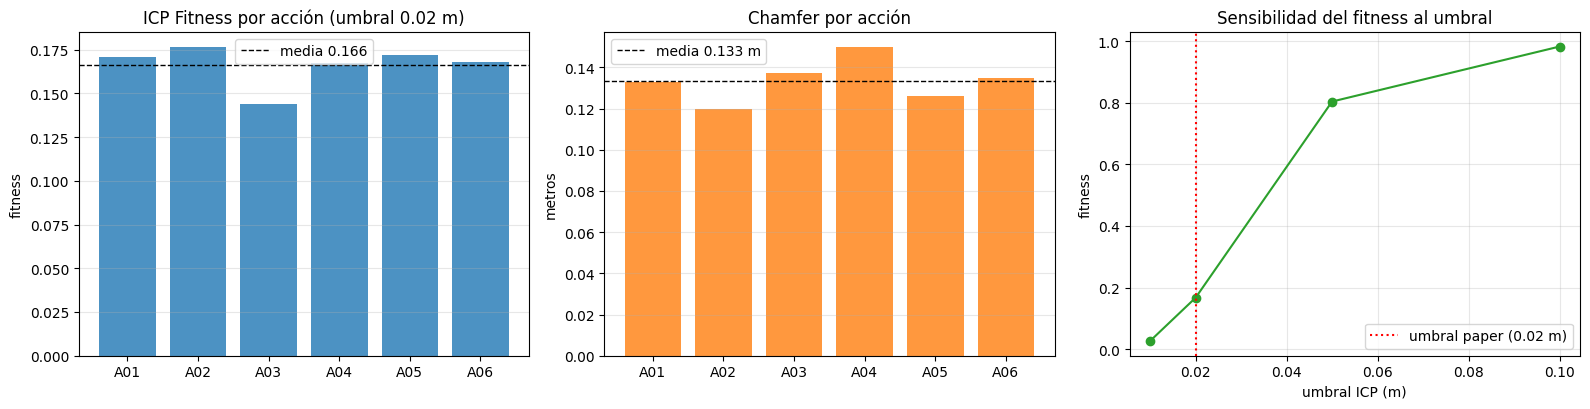

>> metricas_test.png guardado


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
accs = sorted(set(acts_test))
x = np.arange(len(accs))

# Fitness por acción
f_acc = [resultados[UMBRAL_PAPER]['fitness'][acts == a].mean() for a in accs]
axes[0].bar(x, f_acc, color='tab:blue', alpha=0.8)
axes[0].axhline(np.mean(f_acc), color='k', ls='--', lw=1, label=f'media {np.mean(f_acc):.3f}')
axes[0].set_xticks(x); axes[0].set_xticklabels(accs)
axes[0].set_title(f'ICP Fitness por acción (umbral {UMBRAL_PAPER} m)')
axes[0].set_ylabel('fitness'); axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)

# Chamfer por acción
c_acc = [chamfer[acts == a].mean() for a in accs]
axes[1].bar(x, c_acc, color='tab:orange', alpha=0.8)
axes[1].axhline(chamfer.mean(), color='k', ls='--', lw=1, label=f'media {chamfer.mean():.3f} m')
axes[1].set_xticks(x); axes[1].set_xticklabels(accs)
axes[1].set_title('Chamfer por acción')
axes[1].set_ylabel('metros'); axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)

# Fitness vs umbral
fs = [resultados[t]['fitness'].mean() for t in UMBRALES]
axes[2].plot(UMBRALES, fs, 'o-', color='tab:green')
axes[2].axvline(UMBRAL_PAPER, color='r', ls=':', lw=1.5, label=f'umbral paper ({UMBRAL_PAPER} m)')
axes[2].set_xlabel('umbral ICP (m)'); axes[2].set_ylabel('fitness')
axes[2].set_title('Sensibilidad del fitness al umbral')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'metricas_test.png'), dpi=120)
plt.show()
print('>> metricas_test.png guardado')

## 8. Visualización GT vs predicho

Colores de Määttä: colormap `viridis` según distancia al sensor. Se muestra un frame de
cada acción, todos del conjunto de test.

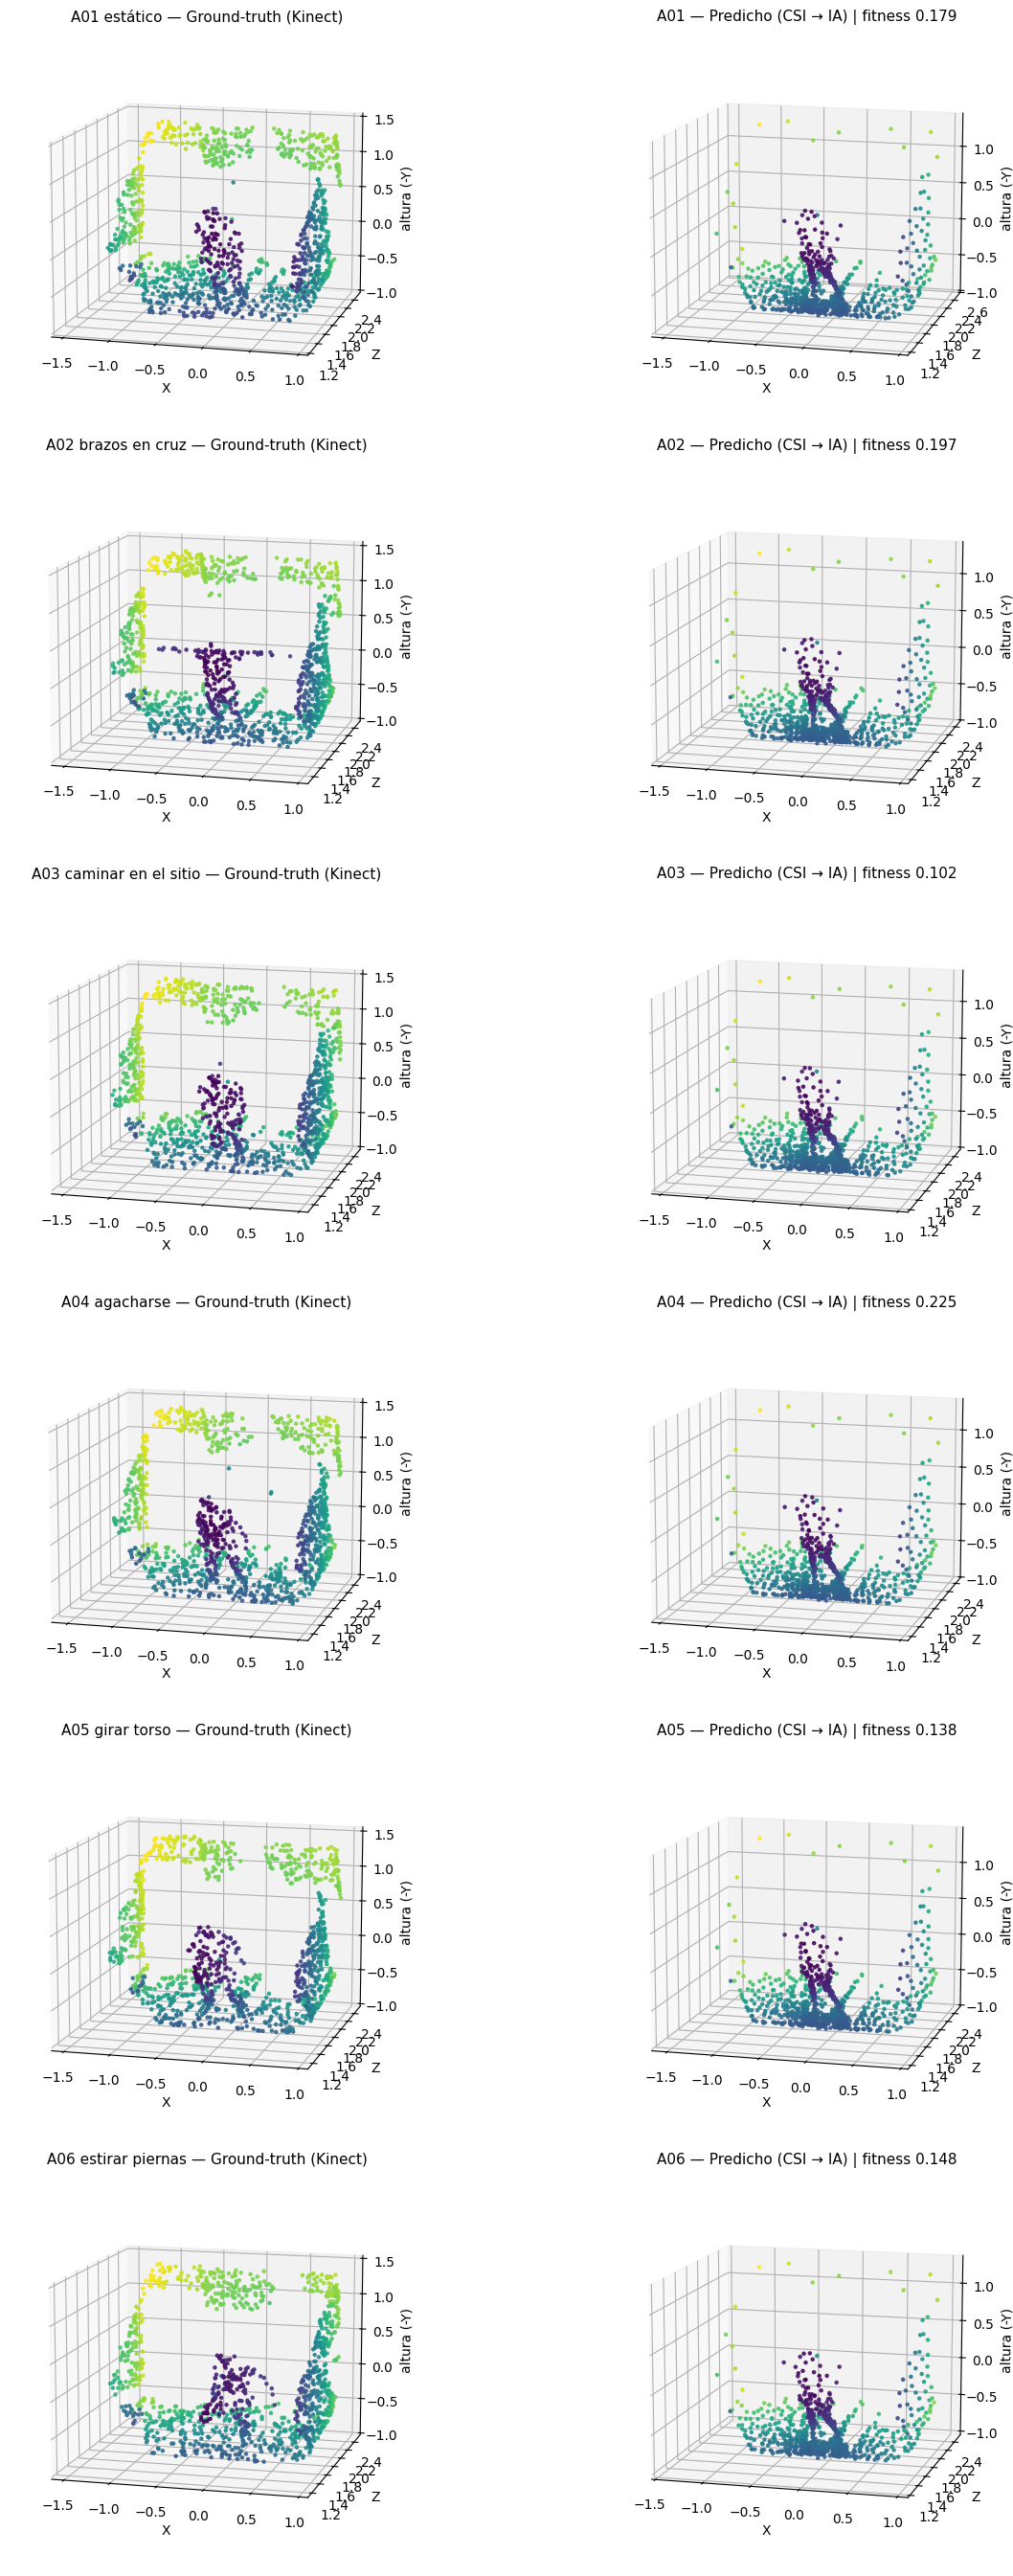

>> test_todas_acciones.png guardado


In [8]:
def plot_nube(ax, P, titulo):
    """Orientación de pie: (X, Z, -Y). Color = distancia al sensor."""
    h, prof, alt = P[:, 0], P[:, 2], -P[:, 1]
    sc = ax.scatter(h, prof, alt, c=np.linalg.norm(P, axis=1),
                    cmap='viridis', s=5, alpha=0.85)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('X'); ax.set_ylabel('Z'); ax.set_zlabel('altura (-Y)')
    ax.view_init(elev=12, azim=-75)
    return sc


accs = sorted(set(acts_test))
fig = plt.figure(figsize=(15, 4.5 * len(accs)))

for fila, a in enumerate(accs):
    k = acts_test.index(a)          # primer frame de test de esa acción
    gt, pm = gts[k], preds_m[k]
    f = resultados[UMBRAL_PAPER]['fitness'][k]

    ax1 = fig.add_subplot(len(accs), 2, fila * 2 + 1, projection='3d')
    plot_nube(ax1, gt, f'{a} {NOMBRES.get(a, "")} — Ground-truth (Kinect)')
    ax2 = fig.add_subplot(len(accs), 2, fila * 2 + 2, projection='3d')
    plot_nube(ax2, pm, f'{a} — Predicho (CSI → IA) | fitness {f:.3f}')

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'test_todas_acciones.png'), dpi=110)
plt.show()
print('>> test_todas_acciones.png guardado')

## 9. Guardar el informe

Escribe `metricas_test.txt` con todas las cifras, listo para citar en la tesis.

In [9]:
L = []
L.append('=' * 68)
L.append('EVALUACIÓN CSI2PointCloud — dataset propio (ESP32-S3 + Azure Kinect)')
L.append('=' * 68)
L.append('')
L.append(f'Modelo      : embedding {model.embedding_dim}, '
         f'{CFG.get("num_encoder_layers","?")}+{CFG.get("num_decoder_layers","?")} capas, '
         f'{model.num_heads} heads')
L.append(f'Parámetros  : {sum(p.numel() for p in model.parameters()):,}')
L.append(f'Entrenamiento: {CFG.get("epochs","?")} épocas, batch {CFG.get("batch_size","?")}, '
         f'lr {CFG.get("lr","?")}, checkpoint de la época {ck.get("epochs","?")}')
L.append(f'Test        : {len(te)} frames (último 15 % cronológico de cada acción)')
L.append(f'Inferencia  : {ms_por_frame:.3f} ms/frame en {device.type.upper()}')
L.append('')
L.append('MÉTRICAS GLOBALES')
L.append('-' * 68)
L.append(f'{"Umbral":>8} | {"ICP Fitness":>12} | {"ICP RMSE (m)":>13} | {"Chamfer (m)":>12}')
for thr in UMBRALES:
    r = resultados[thr]
    marca = '  <-- umbral del paper' if thr == UMBRAL_PAPER else ''
    L.append(f'{thr:8.2f} | {r["fitness"].mean():12.4f} | {r["rmse"].mean():13.4f} | '
             f'{chamfer.mean():12.4f}{marca}')
L.append('')
L.append(f'POR ACCIÓN (umbral {UMBRAL_PAPER} m)')
L.append('-' * 68)
L.append(f'{"Acción":<24} | {"n":>3} | {"Fitness":>8} | {"RMSE (m)":>9} | {"Chamfer (m)":>11}')
for a, nom, n_a, f_a, rm_a, ch_a in filas:
    L.append(f'{a} {nom:<20} | {n_a:3d} | {f_a:8.3f} | {rm_a:9.4f} | {ch_a:11.4f}')
L.append('')
L.append('INTERPRETACIÓN')
L.append('-' * 68)
L.append('El ICP fitness mide cuántos puntos predichos tienen correspondencia dentro del')
L.append('umbral; crece rápido al relajarlo, por lo que debe leerse junto al umbral usado.')
L.append('El Chamfer no depende del umbral y es la medida más estable de la calidad')
L.append('global de la reconstrucción.')
L.append('')
L.append('REFERENCIA (Määttä et al. 2025, Tabla I) — NO COMPARABLE DIRECTAMENTE')
L.append('-' * 68)
L.append('  Subject-based split: ICP Fitness 0.6358 | ICP RMSE 0.0103 m')
L.append('  Room-based split   : ICP Fitness 0.6127 | ICP RMSE 0.0104 m')
L.append('  Tiempo: CPU 137.27 ms | GPU 2.31 ms')
L.append('')
L.append('Diferencias: MM-Fi (40 sujetos, 27 acciones, LiDAR Ouster, escena completa con')
L.append('muebles, split por sujeto/sala, CSI Atheros 5 GHz) frente a este trabajo')
L.append('(1 sujeto, 6 acciones, Azure Kinect, sujeto aislado, split cronológico,')
L.append('CSI ESP32-S3 2.4 GHz).')

texto = '\n'.join(L)
ruta = os.path.join(OUT, 'metricas_test.txt')
with open(ruta, 'w', encoding='utf-8') as f:
    f.write(texto + '\n')

json.dump({'umbrales': {str(t): {'fitness': float(resultados[t]['fitness'].mean()),
                                 'rmse': float(resultados[t]['rmse'].mean())}
                        for t in UMBRALES},
           'chamfer': float(chamfer.mean()),
           'ms_por_frame': float(ms_por_frame),
           'n_test': len(te),
           'por_accion': {f[0]: {'n': f[2], 'fitness': float(f[3]),
                                 'rmse': float(f[4]), 'chamfer': float(f[5])} for f in filas}},
          open(os.path.join(OUT, 'metricas_test.json'), 'w'), indent=2)

print(texto)
print(f'\n>> guardado: {ruta}')
print(f'>> guardado: {os.path.join(OUT, "metricas_test.json")}')

EVALUACIÓN CSI2PointCloud — dataset propio (ESP32-S3 + Azure Kinect)

Modelo      : embedding 256, 3+3 capas, 4 heads
Parámetros  : 9,086,979
Entrenamiento: 50 épocas, batch 24, lr 0.0001, checkpoint de la época 50
Test        : 112 frames (último 15 % cronológico de cada acción)
Inferencia  : 2.343 ms/frame en CUDA

MÉTRICAS GLOBALES
--------------------------------------------------------------------
  Umbral |  ICP Fitness |  ICP RMSE (m) |  Chamfer (m)
    0.01 |       0.0262 |        0.0070 |       0.1333
    0.02 |       0.1667 |        0.0146 |       0.1333  <-- umbral del paper
    0.05 |       0.8040 |        0.0311 |       0.1333
    0.10 |       0.9826 |        0.0385 |       0.1333

POR ACCIÓN (umbral 0.02 m)
--------------------------------------------------------------------
Acción                   |   n |  Fitness |  RMSE (m) | Chamfer (m)
A01 estático             |  18 |    0.171 |    0.0146 |      0.1328
A02 brazos en cruz       |  20 |    0.176 |    0.0146 |      0.1

## 10. Vídeo: ground-truth vs predicho en movimiento

Genera un `.mp4` recorriendo los frames de test en orden cronológico, con la nube real
(Kinect) a la izquierda y la predicha (CSI → IA) a la derecha.

Es lo que una imagen estática no puede mostrar: **si el modelo sigue el movimiento del
sujeto**. Los frames de test son los últimos de cada acción, así que el vídeo reproduce
la secuencia tal como se capturó.

Los ejes se fijan al rango del ground-truth de toda la secuencia (igual que
`visualize_point_clouds()` de `test_model.py`, que usa `set_xlim/ylim/zlim` fijos), para
que la cámara no "salte" entre frames y el movimiento sea legible.

In [10]:
import cv2
import matplotlib
matplotlib.use('Agg')          # backend sin ventana: necesario para renderizar a imagen
from matplotlib.backends.backend_agg import FigureCanvasAgg


def limites(nubes, margen=0.05):
    """Rango (min, max) por eje sobre un conjunto de nubes, con margen."""
    P = np.vstack(nubes)
    lo, hi = P.min(axis=0), P.max(axis=0)
    d = (hi - lo) * margen
    return lo - d, hi + d


def frame_a_imagen(gt, pred, titulo, lo, hi, fitness=None, dpi=100):
    """Renderiza un par (GT, predicho) como imagen RGB de numpy."""
    fig = plt.figure(figsize=(12.8, 5.4), dpi=dpi)
    fig.suptitle(titulo, fontsize=14)

    for col, (P, nombre, cmap) in enumerate([
            (gt,   'Ground-truth (Kinect)', 'viridis'),
            (pred, 'Predicho (CSI → IA)',   'viridis')]):
        ax = fig.add_subplot(1, 2, col + 1, projection='3d')
        h, prof, alt = P[:, 0], P[:, 2], -P[:, 1]
        ax.scatter(h, prof, alt, c=np.linalg.norm(P, axis=1),
                   cmap=cmap, s=4, alpha=0.85)
        # Ejes fijos: imprescindible para que el vídeo no "salte"
        ax.set_xlim(lo[0], hi[0])
        ax.set_ylim(lo[2], hi[2])
        ax.set_zlim(-hi[1], -lo[1])
        ax.set_autoscale_on(False)
        t = nombre if fitness is None or col == 0 else f'{nombre} | fitness {fitness:.3f}'
        ax.set_title(t, fontsize=11)
        ax.set_xlabel('X (m)'); ax.set_ylabel('Z (m)'); ax.set_zlabel('altura (m)')
        ax.view_init(elev=12, azim=-75)

    fig.tight_layout()
    canvas = FigureCanvasAgg(fig)
    canvas.draw()
    img = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()   # RGBA -> RGB
    plt.close(fig)
    return img


def hacer_video(indices, ruta_mp4, titulo_base='', fps=10):
    """Crea un mp4 con los frames indicados (índices sobre preds_m/gts)."""
    lo, hi = limites([gts[k] for k in indices])
    t0 = time.time()
    imgs = []
    for j, k in enumerate(indices):
        a = acts_test[k]
        tit = (f'{titulo_base}{a} {NOMBRES.get(a, "")} — frame {j+1}/{len(indices)}')
        imgs.append(frame_a_imagen(gts[k], preds_m[k], tit, lo, hi,
                                   resultados[UMBRAL_PAPER]['fitness'][k]))
        if (j + 1) % 20 == 0:
            print(f'  renderizados {j+1}/{len(indices)}...', flush=True)

    h, w, _ = imgs[0].shape
    vw = cv2.VideoWriter(ruta_mp4, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    for img in imgs:
        vw.write(cv2.cvtColor(img, cv2.COLOR_RGB2BGR))   # OpenCV usa BGR
    vw.release()

    mb = os.path.getsize(ruta_mp4) / 1e6
    print(f'>> {os.path.basename(ruta_mp4)}: {len(imgs)} frames, {w}x{h}, '
          f'{fps} fps, {mb:.1f} MB  ({time.time()-t0:.0f}s)')
    return ruta_mp4


# --- Vídeo de TODAS las acciones seguidas ---
orden = sorted(range(len(te)), key=lambda k: (acts_test[k], k))
ruta = hacer_video(orden, os.path.join(OUT, 'video_test_completo.mp4'), fps=10)

  renderizados 20/112...


  renderizados 40/112...


  renderizados 60/112...


  renderizados 80/112...


  renderizados 100/112...


>> video_test_completo.mp4: 112 frames, 1280x540, 10 fps, 4.8 MB  (13s)


## 11. Vídeo de una acción concreta

Un `.mp4` por acción, útil para la defensa (p. ej. mostrar A04 *agacharse*, donde el
movimiento vertical es más visible, o A03 *caminar en el sitio*, que es la de peor fitness).

Cambia `ACCION` y reejecuta, o pon `TODAS = True` para generar las seis de una vez.

In [11]:
ACCION = 'A04'     # A01..A06
TODAS  = False     # True = genera un vídeo por cada acción
FPS    = 5         # 5 fps = cámara lenta (los datos son 10 Hz); sube a 10 para tiempo real

objetivo = sorted(set(acts_test)) if TODAS else [ACCION]
generados = []

for a in objetivo:
    idx = [k for k in range(len(te)) if acts_test[k] == a]
    if not idx:
        print(f'{a}: sin frames de test'); continue
    ruta_a = os.path.join(OUT, f'video_test_{a}.mp4')
    generados.append(hacer_video(idx, ruta_a, fps=FPS))

print(f'\n{len(generados)} vídeo(s) en {OUT}')

>> video_test_A04.mp4: 19 frames, 1280x540, 5 fps, 0.8 MB  (2s)

1 vídeo(s) en C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados


## 12. GIF animado y reproducción en el notebook

El `.mp4` generado con OpenCV (códec `mp4v`) no siempre se reproduce dentro de Jupyter.
Esta celda crea además un **GIF**, que sí se ve en cualquier notebook y se puede insertar
directamente en presentaciones.

Para los `.mp4`, ábrelos con el reproductor del sistema desde la carpeta de resultados.

>> video_test_A04.gif: 19 frames, 0.5 MB



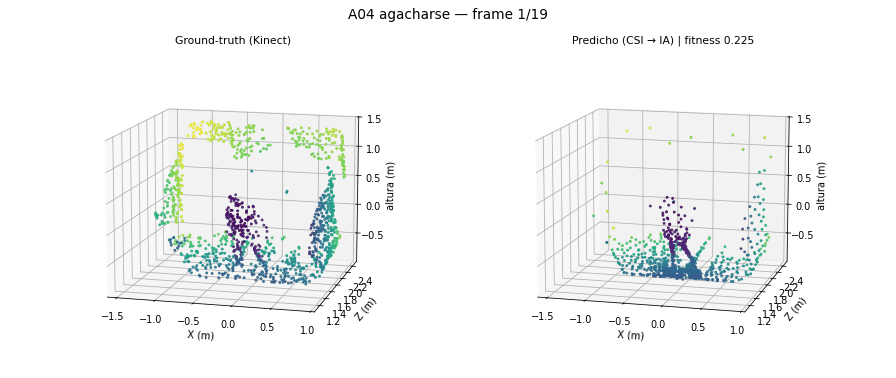

In [12]:
from PIL import Image
from IPython.display import Image as IPImage, display

ACCION_GIF = 'A04'
DPI_GIF    = 70     # menor dpi = GIF más ligero

idx = [k for k in range(len(te)) if acts_test[k] == ACCION_GIF]
lo, hi = limites([gts[k] for k in idx])

frames = []
for j, k in enumerate(idx):
    img = frame_a_imagen(gts[k], preds_m[k],
                         f'{ACCION_GIF} {NOMBRES.get(ACCION_GIF, "")} — frame {j+1}/{len(idx)}',
                         lo, hi, resultados[UMBRAL_PAPER]['fitness'][k], dpi=DPI_GIF)
    frames.append(Image.fromarray(img))

ruta_gif = os.path.join(OUT, f'video_test_{ACCION_GIF}.gif')
frames[0].save(ruta_gif, save_all=True, append_images=frames[1:],
               duration=200, loop=0, optimize=True)   # 200 ms/frame = 5 fps

print(f'>> {os.path.basename(ruta_gif)}: {len(frames)} frames, '
      f'{os.path.getsize(ruta_gif)/1e6:.1f} MB\n')
display(IPImage(filename=ruta_gif))